# Downscaling lab: evaluation

Compares every evaluated run of one experiment with the regional climate model (RCM) "truth" and with the published
CORDEX-ML-Bench entries. Heavy computation happens beforehand in `dslab evaluate` (batch job), which writes small
`scores.json` / `diagnostics.nc` files per run and split; this notebook only loads and plots them (≈ 30 s).

**How to read it.** Every figure cell starts with a caption generated from the experiment configuration: what is
shown, what the models were *trained* on, and what they are *evaluated* on. Below each figure, a short findings note
summarises what it shows; these notes are dated snapshots and must be updated when runs are added or changed.

**Run it:** JupyterHub, preset *interactive* (10 GB), kernel **dslab**; or headless with `sbatch jobs/notebook.sbatch`.
Colours are fixed per run; the RCM truth is always black, the climatology floor and published entries grey.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from dslab import plotting as P
from dslab import results
from dslab.experiment import Experiment

EXPERIMENT = "alps_esd"                 # e.g. "alps_emulator" for the Emulator experiment
EXP = Experiment.load(EXPERIMENT)
# Runs shown: the deterministic U-Net baseline and adaptive flow matching. The earlier baselines (climatology,
# linear, deepesd) are still on disk; add their names here to show them again.
RUNS = [r for r in ["unet", "afm"] if r in results.list_runs(EXP)]
SPLIT = "historical_perfect"            # main test split
FUTURE = next(s for s, t in EXP.reference["splits"].items() if t == "lower_right")
# Published entries listed in the tables (the strip plots and rank tables use all of them)
REF_MODELS = ["Prithvi-UNet-orog", "RCMGEM-mv-orog", "CorrDiff-TW1_NTNU-CWA-orog", "FlowMatching-v1-orog",
              "DetUNet-orog", "DeepESD-IFCAv1-orog"]
FIG_DIR = EXP.eval_dir / "figures"      # None: do not save figures

P.setup_style()
COLORS = P.run_colors(RUNS)
save = (lambda name: FIG_DIR / f"{name}.png") if FIG_DIR else (lambda name: None)
scores = results.load_scores(EXP)
cap = lambda shown, splits=SPLIT: display(results.caption(EXP, shown, splits, RUNS, scores))  # noqa: E731


def fmt(v):
    if isinstance(v, str) or pd.isna(v):
        return "" if not isinstance(v, str) else v
    a = abs(v)
    return f"{v:.3f}" if a < 0.1 else f"{v:.2f}" if a < 10 else f"{v:.1f}" if a < 100 else f"{v:.0f}"


print(EXP.description, "| runs:", RUNS)

ESD pseudo-reality, ALPS, CNRM-CM5-driven ALADIN63, train 1961-1980 | runs: ['unet', 'afm']


## Experiments

Two kinds of "experiment" appear in this notebook: the **benchmark experiments** (which data a model is trained and
tested on, defined by CORDEX-ML-Bench) and the **model runs** (which method is trained, defined by us). Every model
run is trained within one benchmark experiment and then evaluated on that experiment's test sets.

### Benchmark experiments (CORDEX-ML-Bench)

The task is the same in both experiments: learn the mapping from large-scale atmospheric predictors (u, v, t, z, q
at 850/700/500 hPa on a 16 × 16 grid at 2°) to daily precipitation (`pr`) and maximum temperature (`tasmax`) on the
128 × 128 grid (12.5 km) of a regional climate model (RCM; here ALADIN63 driven by the global model CNRM-CM5). Both
experiments train on *perfect* predictors; they differ in the training period and therefore in what the tests probe.

| | **Experiment 1: ESD pseudo-reality** (`alps_esd`) | **Experiment 2: Emulator hist+future** (`alps_emulator`) |
|---|---|---|
| idea | classic statistical downscaling: learn from a present-day period, apply it to other periods | RCM emulator: learn from present-day and end-of-century climate, fill in between |
| training period | 1961–1980 (20 years) | 1961–1980 + 2080–2099 (40 years) |
| main question | does the model **extrapolate** to a warmer climate it has never seen? | does it **interpolate** to an intermediate climate and transfer to other GCMs? |
| tests | 1 perfect cross-validation 1981–2000 · 2 imperfect cross-validation · 3 perfect extrapolation 2041–2060 + 2080–2099 · 4 imperfect extrapolation · 5 perfect extrapolation with another GCM | 1 perfect cross-validation · 2 imperfect cross-validation · 3 perfect interpolation 2041–2060 · 4 imperfect interpolation · 5/6 perfect/imperfect interpolation with another GCM |
| published scorecard (paper Figs. S12/S13) | Test 1 (upper-left triangle), Test 3 (lower-right) | Test 1, Test 3 |

The test names combine three ideas:

* **Perfect vs. imperfect predictors.** *Perfect* predictors are the RCM's own fields upscaled to the 2° grid: they
  are consistent with the targets, so all remaining error is downscaling error. *Imperfect* predictors are the fields
  of the driving GCM, which is what a model receives in a real application; they add GCM biases and mismatches between
  predictors and targets.
* **Cross-validation / extrapolation / interpolation** say where the test period lies relative to the training period:
  same climate, outside it, or between two training periods.
* **GCM transferability.** The same RCM driven by a different GCM (MPI-ESM-LR instead of CNRM-CM5): does the model
  generalise beyond the one simulation it was trained on?

The table below is generated from the experiment configuration: it lists this experiment's tests, the split that
implements each, and which runs have been evaluated on it so far.

In [2]:
display(Markdown(f"**{EXP.name}**: {EXP.description}. Truth: {EXP.truth}."))
results.benchmark_tests(EXP, RUNS)

**alps_esd**: ESD pseudo-reality, ALPS, CNRM-CM5-driven ALADIN63, train 1961-1980. Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.

,name,split,period,predictors,driving GCM,in published scorecard,evaluated runs
test,,,,,,,
Test 1,perfect cross-validation,historical_perfect,1981–2000,perfect (upscaled RCM),CNRM-CM5,yes,"unet, afm"
Test 2,imperfect cross-validation,historical_imperfect,1981–2000,imperfect (GCM),CNRM-CM5,,—
Test 3,perfect extrapolation,mid_end_century_perfect,2041–2060 + 2080–2099,perfect (upscaled RCM),CNRM-CM5,yes,"unet, afm"
Test 4,imperfect extrapolation,mid_end_century_imperfect,2041–2060 + 2080–2099,imperfect (GCM),CNRM-CM5,,—
Test 5,perfect extrapolation (GCM transferability),mid_end_century_perfect_MPI-ESM-LR,2041–2060 + 2080–2099,perfect (upscaled RCM),MPI-ESM-LR,,—


### Predictors and downscaled variables

Every model learns one mapping, from the **predictors** to the **target variables**:

* **Predictors (input):** 15 daily fields on the coarse grid, five atmospheric quantities at three pressure levels.
  Wind (u, v) and geopotential height (z) describe the circulation; temperature (t) and specific humidity (q)
  describe the air mass. In the *perfect* tests they are the RCM's own fields regridded to the 2° grid, in the
  *imperfect* tests the same fields from the driving GCM.
* **Static field (input):** orography on the target grid, which carries the terrain detail the coarse grid cannot
  resolve.
* **Target variables (downscaled output):** daily precipitation (`pr`) and daily maximum near-surface temperature
  (`tasmax`) on the RCM grid. All scores and figures in this notebook refer to these two variables.

The table is read from the experiment configuration and the training files.

In [3]:
results.variables_table(EXP)

description  \
role                variable                                               
predictor           u                                      Eastward Wind   
                    v                                     Northward Wind   
                    t                                    Air Temperature   
                    z                                Geopotential Height   
                    q                                  Specific Humidity   
static              orog                                Surface Altitude   
target (downscaled) pr                                     Precipitation   
                    tasmax    Daily Maximum Near-Surface Air Temperature   

                                         levels             channels   units  \
role                variable                                                   
predictor           u         850, 700, 500 hPa  u_850, u_700, u_500     m/s   
                    v         850, 700, 500 hPa  v_850, v_700, v_500     m/s   
                    t         850, 700, 500 hPa  t_850, t_700, t_500       K   
                    z         850, 700, 500 hPa  z_850, z_700, z_500       m   
                    q         850, 700, 500 hPa  q_850, q_700, q_500   kg/kg   
static              orog                surface                 orog       m   
target (downscaled) pr                  surface                   pr  mm/day   
                    tasmax              surface               tasmax       K   

                                                                 grid  
role                variable                                           
predictor           u         16 × 16, 2° lat/lon (32–62°N, 4°W–26°E)  
                    v         16 × 16, 2° lat/lon (32–62°N, 4°W–26°E)  
                    t         16 × 16, 2° lat/lon (32–62°N, 4°W–26°E)  
                    z         16 × 16, 2° lat/lon (32–62°N, 4°W–26°E)  
                    q         16 × 16, 2° lat/lon (32–62°N, 4°W–26°E)  
static              orog        128 × 128, 12.5 km, Lambert conformal  
target (downscaled) pr          128 × 128, 12.5 km, Lambert conformal  
                    tasmax      128 × 128, 12.5 km, Lambert conformal

How the two runs use them (both predict `pr` and `tasmax` jointly, one field each per day; predictions are
converted back to mm/day and K before evaluation):

| run | input channels on the 128 × 128 grid | targets as seen in training |
|---|---|---|
| `unet` | 16: the 15 predictors (standardised per channel and coarse grid point, bilinearly interpolated to the target grid points) + orography (standardised) | sqrt(pr) and tasmax, each standardised per grid point |
| `afm` | 17: the same 15 interpolated predictors + orography + latitude of each grid point (both standardised; latitude comes from the grid coordinates, not from a data file) | raw pr and tasmax, each z-scored with one mean and standard deviation per variable |

Training and model selection use only the training file, never a test set:

In [4]:
display(Markdown("\n".join(f"- {results.describe_split(EXP, s)}" for s in ["train", "val"])))

- `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields)
- `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields)

### Model runs

Each run is one model fitted on `train` (hyperparameters / checkpoint selection on `val`) and evaluated on the test
splits. This notebook compares the deterministic **U-Net** baseline with **adaptive flow matching (AFM)**, a generative
model implemented as described by Debeire et al. (2026, arXiv:2604.03459) for their "AFM-baseline", i.e. without the
physics-constraint (conservation) loss. The earlier rungs of the ladder (climatology, linear, DeepESD) are kept on
disk for reference; their results are in `NOTES.md` and the git history of this notebook.

| run | what it is | input → output | training (here) | why it is on the ladder |
|---|---|---|---|---|
| `unet` | residual U-Net (9.8 M parameters) on the target grid; predictors interpolated to every grid point, orography added | 16 × 128 × 128 → 2 × 128 × 128, one field per day | MSE on per-grid-point standardised sqrt(pr), tasmax; early stopping on `val`; 1 A100, 7 min | deterministic baseline: the conditional mean |
| `afm` | encoder *E* (SongUNet-L) gives a first estimate; a denoiser *D* (SongUNet-L) turns *E* + noise into a sample by integrating a learned flow in 50 steps; the noise scale per variable adapts to the encoder's error (23.8 M parameters in total) | 17 × 128 × 128 (predictors, orography, latitude) → 12 members × 2 × 128 × 128 (5 members for the two future periods) | flow-matching loss + 0.25 × encoder MSE (paper Eq. 3) on z-scored raw pr, tasmax; 2 M samples, checkpoint selection on `val`; 1 A100, 2.2 h (+ 1.3 h sampling) | generative: realistic texture, extremes and calibrated ensembles |

**AFM in a nutshell.** Training draws a time *t* ∈ [0, 1] and builds a noisy state between the encoder estimate and
the truth, x_t = (1 − t)·E + t·x₁ + σ_t·ε with σ_t = (1 − t)·σ_max; the denoiser learns to recover x₁ from x_t. At
inference, each member starts from E + σ_max·ε with its own noise ε and is moved to the data in 50 Euler steps.
Because σ_max tracks the encoder error, the noise injected matches the uncertainty that the deterministic part
leaves. Details and the few choices the papers leave open: `src/dslab/models/afm.py`.

For scale: CorrDiff-TW1, the most expensive published entry, reports 8 × H200 × 17.5 h (about 140 GPU-hours) of
training. The table below is generated from the run directories.

In [5]:
results.run_info(EXP, RUNS)[["model", "summary", "n_params", "hardware", "fit_seconds", "epochs", "selected"]]

,model,summary,n_params,hardware,fit_seconds,epochs,selected
run,,,,,,,
unet,unet,residual U-Net on the target grid; predictors ...,9841922,NVIDIA A100-SXM4-80GB,419.2,35.000000,"{'pr': {'best_epoch': 26, 'val_rmse': 3.737090..."
afm,afm,adaptive flow matching (Debeire et al. 2026 wi...,23767108,NVIDIA A100-SXM4-80GB,7828.4,304.201977,"{'pr': {'best_samples': 1100032, 'val_rmse_enc..."


## Metrics in brief

Two families of metrics answer different questions:

* **Accuracy** — does the model get each *day* right? (RMSE, MAE, correlation, CRPS). A deterministic regression
  trained with MSE predicts the conditional mean, which minimises these by construction but is too smooth.
* **Realism / climate statistics** — does the model produce the right *climate*: mean, extremes, variability,
  spatial texture, distribution? (Mean bias, SDII, Rx1day, TXx, IAV, RALSD, LHD, PSS). These ignore the timing of
  individual days, so a realistic generative model can do well here while having a larger day-by-day error.

Generative models are scored with the ensemble mean for RMSE / mean bias and with individual members for the
realism metrics, as in the benchmark. A good downscaling model needs both families.

| metric | what it measures | units | ideal | published ALPS ESD range (min · median · max, 40 entries) | how to read it |
|---|---|---|---|---|---|
| **RMSE** | daily error over all days and grid points (ensemble mean) | mm/day, K | 0 | pr 3.63 · 4.63 · 6.46; tasmax 1.26 · 1.56 · 9.94 | day-by-day accuracy; favours smooth predictions |
| **Mean Bias** | bias map of the time mean, reduced as RMS over grid points | mm/day, K | 0 | pr 0.16 · 0.38 · 1.39; tasmax 0.09 · 0.29 · 6.35 | systematic climate error; positive and negative regions do **not** cancel, the sign is lost (see "Bias (domain mean)") |
| **SDII** (pr) | bias of mean precipitation on wet days (≥ 1 mm/day) | mm/day | 0 | 0.41 · 1.42 · 3.73 | rain intensity; drizzle (many light-rain days) lowers it |
| **Rx1day** (pr) | bias of the mean annual maximum daily precipitation | mm/day | 0 | 5.8 · 12.3 · 28.9 | heavy-rain extremes |
| **TXx** (tasmax) | bias of the mean annual maximum of tasmax | K | 0 | 0.41 · 1.06 · 8.23 | hot extremes |
| **IAV** (tasmax) | bias of the standard deviation of annual means | K | 0 | 0.075 · 0.14 · 0.37 | year-to-year variability |
| **RALSD** | mean squared dB difference between time-mean radial power spectra, over 90 bins incl. 25 beyond Nyquist (one member) | dB² | 0 | pr 0.09 · 7.4 · 377; tasmax 0.025 · 4.7 · 205 | spatial texture: < 1 very realistic, > 10 clearly too smooth or too noisy; dominated by pixel-scale detail (section 6) |
| **LHD** (pr) | RMS dB difference between histograms of all daily values (10 mm/day bins, bins with > 10 counts) | dB | 0 | 0.31 · 1.41 · 4.27 | shape of the distribution incl. heavy tail; > 3 = clearly wrong frequencies |
| **PSS** (tasmax) | overlap of the normalised histograms (1 °C bins) | – | 1 | 0.81 · 0.97 · 0.99 | distribution similarity; saturates near 0.97–0.99 |
| MAE | mean absolute daily error | mm/day, K | 0 | – | like RMSE, less sensitive to large errors |
| Bias (domain mean) | signed mean error over all days and points | mm/day, K | 0 | – | the sign that "Mean Bias" hides |
| Corr (temporal) | Pearson correlation over time at each grid point, averaged | – | 1 | – | timing of day-to-day variations |
| P99 bias | RMS over grid points of the 99th-percentile bias map | mm/day, K | 0 | – | local extremes (daily, not annual) |
| Wet-day freq bias (pr) | RMS of the bias map of the fraction of days ≥ 1 mm/day | – | 0 | – | drizzle / missing rain days |
| CRPS | continuous ranked probability score (fair, per ensemble) | mm/day, K | 0 | – | probabilistic accuracy; equals MAE for deterministic runs |
| Spread/skill | ensemble spread / RMSE of the ensemble mean | – | 1 | – | < 1 over-confident, > 1 under-confident (ensembles only) |
| MCB | miscalibration: mean squared deviation of the rank histogram from flat (as in Debeire et al. 2026) | – | 0 | – | ensemble calibration in one number (ensembles only) |

Exact definitions, as implemented by the benchmark organisers, are in `docs/metric_definitions.md`. Note that the
AFM paper defines RALSD differently (square root of the mean squared dB difference, spectra averaged over members),
so its RALSD values are not comparable with the benchmark's.

## 1. Training of the neural runs

**Shown:** training curves of the neural runs, one panel per run: training loss (grey) and validation loss (colour) against passes over the training data; the dot marks the checkpoint that is kept. U-Net: MSE of standardised targets; AFM: L_AFM + 0.25 L_enc (validation with fixed noise draws, EMA weights).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

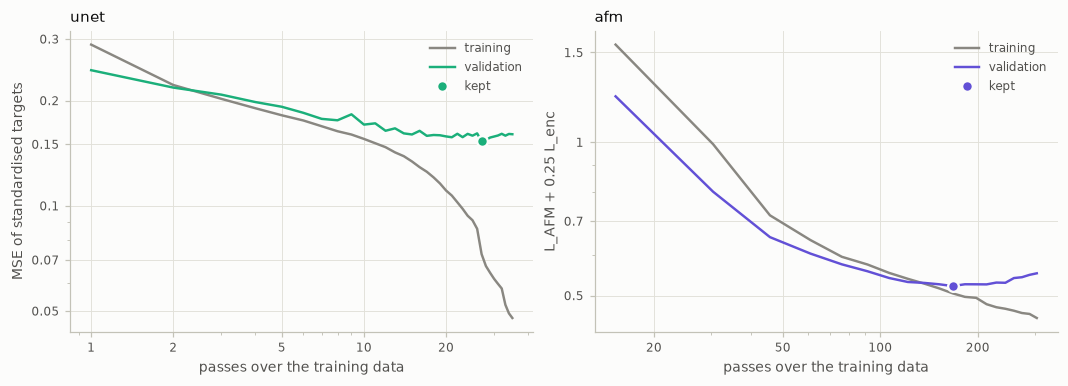

In [6]:
hist = {r: h for r in RUNS if (h := results.load_history(EXP, r)) is not None}
cap("training curves of the neural runs, one panel per run: training loss (grey) and validation loss (colour) "
    "against passes over the training data; the dot marks the checkpoint that is kept. U-Net: MSE of standardised "
    "targets; AFM: L_AFM + 0.25 L_enc (validation with fixed noise draws, EMA weights).", "val")
P.fig_training_curves(hist, COLORS, save=save("training_curves")) if hist else print("no neural runs yet");

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **U-Net** (9.8 M parameters) reaches its lowest validation loss after 26 passes (0.153), then overfits: training
  loss keeps falling (0.048) while validation loss rises. Early stopping keeps the epoch-26 weights.
- **AFM** (23.8 M parameters) trained on 2.0 M samples, i.e. 304 passes over the 6,575 training days, in 2.2 h on
  one A100. Validation loss is lowest after 1.1 M samples (167 passes; 0.522), then rises to 0.553 while training
  loss keeps falling (0.505 → 0.452): the denoiser overfits the 18 training years. The rise is entirely in the
  flow-matching term (0.458 → 0.498); the encoder term keeps improving. The 1.1 M checkpoint is the one kept, so
  longer training would not help without more data or regularisation.
- The adaptive noise scale σ_max fell from its start value 1 to 0.64 (pr) and 0.29 (tasmax) in standardised units
  at the kept checkpoint: the encoder leaves about twice as much unexplained variability for precipitation.
- The two panels show different losses; their values cannot be compared.

## 2. Scorecard against the published entries

The 12 metrics of the benchmark paper (supplement Figs. S12/S13), computed exactly as in the organisers' code. Each
grey dot is one published ALPS ESD entry (with- and without-orography variants count separately); diamonds are our
runs. The first table lists the scores, the second how many of the published entries score **better** than each of
our runs (e.g. `2 / 40`: only two published entries are better).

**Shown:** the 12 published scorecard metrics: published entries (grey dots) and our runs (diamonds); lower is better except PSS.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

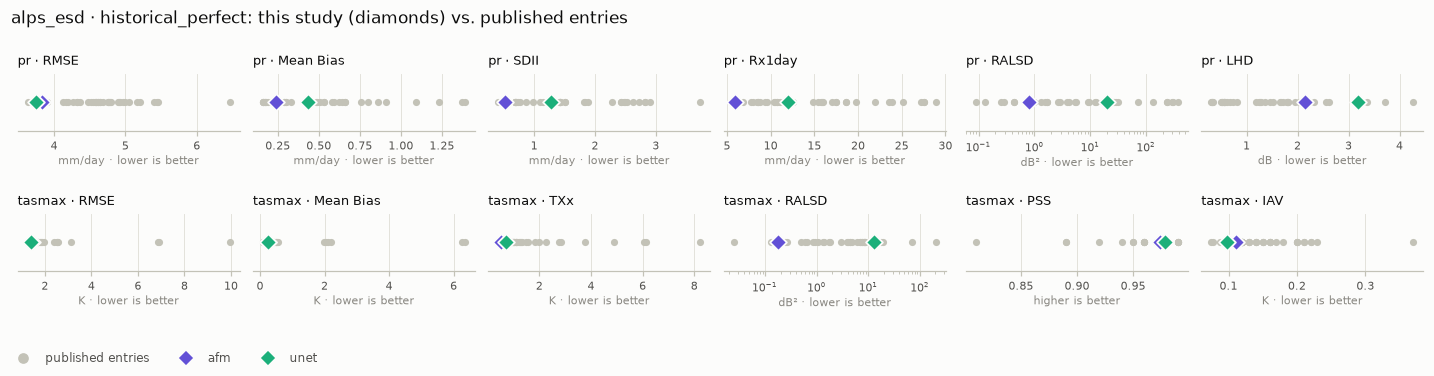

In [7]:
def show_card(card):
    def best(col):
        target = col.max() if col.name[-1] in ("PSS", "Corr (temporal)") else col.abs().min()
        return ["font-weight: 600; background-color: #cde2fb" if pd.notna(v) and abs(v) == abs(target) else ""
                for v in col]
    return card.style.format(fmt).apply(best, axis=0)


cap("the 12 published scorecard metrics: published entries (grey dots) and our runs (diamonds); lower is better "
    "except PSS.")
card = results.scorecard(EXP, SPLIT, RUNS, scores=scores)
P.fig_scorecard_strips(card, COLORS, title=f"{EXP.name} · {SPLIT}: this study (diamonds) vs. published entries",
                       save=save(f"scorecard_{SPLIT}"))
plt.show()
display(show_card(results.scorecard(EXP, SPLIT, RUNS, REF_MODELS, scores=scores)))
display(results.rank_vs_published(card).style.set_caption("number of published entries that score better"))

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)* — historical test period
- **AFM vs. U-Net:** the AFM is better on 7 of 12 metrics: all realism metrics plus pr Mean Bias. The U-Net keeps
  the lower RMSE (pr 3.75 vs. 3.83 mm/day, tasmax 1.40 vs. 1.46 K) and is slightly better on PSS and IAV; tasmax
  Mean Bias is a tie (0.24 vs. 0.25 K). This is the expected trade: the ensemble mean of a generative model is close to,
  but not quite as good as, a regression trained for the conditional mean.
- **Extremes and texture:** among the 40 published entries, only RCMGEM-mv-orog beats the AFM on pr Rx1day (5.79 vs.
  5.90 mm/day) and tasmax TXx (0.41 vs. 0.52 K); two beat it on pr SDII (0.52) and tasmax RALSD (0.18 dB²). pr
  RALSD drops from 19.7 (U-Net) to 0.81 dB² (9 published entries better).
- **Weak spot: pr LHD 2.15 dB** (31 entries better; U-Net 3.18). The histogram matches within 0.5 dB up to about
  100 mm/day but has too few days above 150 mm/day (section 7); the generative entries with low LHD (0.3) get this far
  tail right.
- pr RMSE: the U-Net is third of all entries (only Prithvi-UNet-orog 3.63 and RCMGEM-mv-orog 3.74 are lower), the AFM
  fifth (CorrDiff-TW1, 3.77, also lower). RCMGEM-mv-orog is ahead of the AFM on all 12 metrics (IAV a tie).

**Future period.** For ESD the benchmark pools 2041–2060 and 2080–2099. The models never saw this climate,
so this measures extrapolation. Which period the published LHD/PSS values refer to cannot be determined from the
organisers' code; read those two with care.

**Shown:** the 12 published scorecard metrics for the future period; same layout as above.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

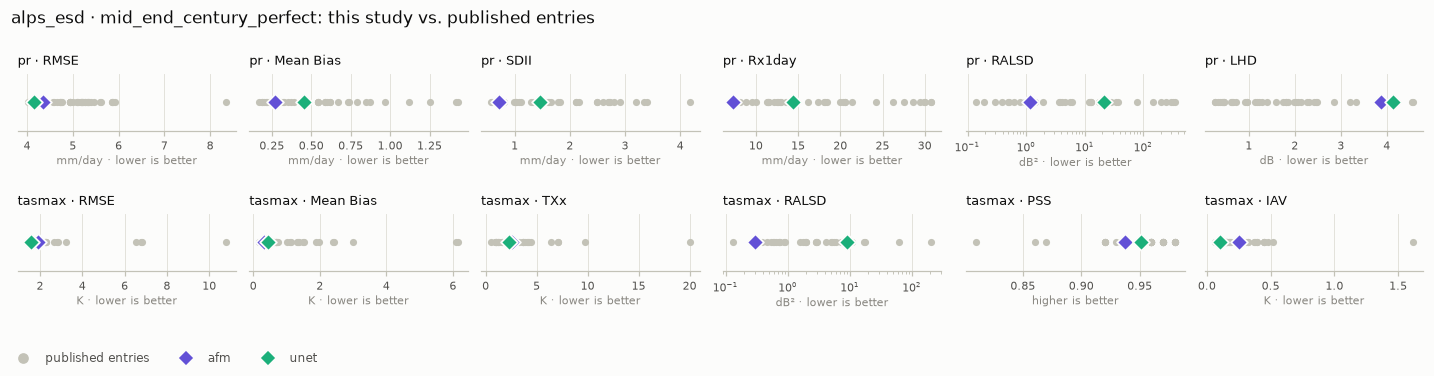

In [8]:
cap("the 12 published scorecard metrics for the future period; same layout as above.", FUTURE)
card_f = results.scorecard(EXP, FUTURE, RUNS, scores=scores)
P.fig_scorecard_strips(card_f, COLORS, title=f"{EXP.name} · {FUTURE}: this study vs. published entries",
                       save=save(f"scorecard_{FUTURE}"))
plt.show()
display(show_card(results.scorecard(EXP, FUTURE, RUNS, REF_MODELS, scores=scores)))
display(results.rank_vs_published(card_f).style.set_caption("number of published entries that score better"))

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)* — future period (extrapolation)
- **Precipitation:** the AFM keeps its advantages. Its Rx1day bias (7.3 mm/day) is lower than that of every
  published entry (best published: RCMGEM-mv-orog, 7.7); SDII 0.72 (3 entries better), RALSD 1.16 dB² (9 better).
  pr RMSE 4.36 vs. 4.15 mm/day for the U-Net (the U-Net is 5th of all entries, the AFM 6th).
- **Temperature: the AFM extrapolates worse than the U-Net.** tasmax RMSE 1.92 vs. 1.59 K (17 vs. 3 published entries
  better), TXx 2.60 vs. 2.24 K, PSS 0.938 vs. 0.951, IAV 0.255 vs. 0.103 K. Only its texture stays excellent
  (RALSD 0.30 dB², 1 entry better). The cause is a cold bias on hot summer days at the end of the century (sections 8
  and 9).
- Both pr LHD values are poor here (AFM 3.87, U-Net 4.13 dB; 37–38 entries better), for the same far-tail reason as
  in the historical period.

## 3. All metrics, all splits

Scorecard plus development metrics (see "Metrics in brief"). `val` is what model selection sees; the test splits
should only be looked at for finished models.

In [9]:
def all_metrics(split):
    s = scores[(scores.split == split) & scores.run.isin(RUNS)]
    return s.pivot_table(index="run", columns=["variable", "metric"], values="value", sort=False).reindex(RUNS)

for split in ["val", SPLIT, FUTURE]:
    cap("all metrics (rows: runs; columns: variable and metric).", split)
    display(all_metrics(split).style.format(fmt))

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **Dry bias removed:** the U-Net's domain-mean pr bias is −0.39 mm/day (−13% of the 3.0 mm/day mean), caused by
  training MSE on sqrt(pr) (Jensen's inequality). The AFM, trained on raw pr and sampling instead of averaging, is at
  −0.09 mm/day (−3%) on the test period and −0.10 on validation.
- **Probabilistic skill:** the AFM's CRPS is 23–24% lower than the U-Net's (pr 1.18 vs. 1.53 mm/day, tasmax 0.77 vs.
  1.01 K; for the deterministic U-Net CRPS equals MAE). Its local extremes are closer too: P99 bias 2.6 vs. 5.7 mm/day.
- **Day-to-day accuracy is slightly lower:** pr correlation 0.80 vs. 0.81, MAE 1.65 vs. 1.53 mm/day; tasmax
  correlation 0.978 vs. 0.980. The AFM is slightly too warm (+0.21 K domain mean), the U-Net slightly too cold (−0.17 K).
- Validation and test scores agree for both models (AFM pr RMSE 3.81 vs. 3.83 mm/day, tasmax 1.45 vs. 1.46 K), so the
  two validation years remain a reliable stand-in for model selection.
- **Future:** the AFM's tasmax RMSE grows from 1.46 K to 1.54 K (2041–2060) and 2.23 K (2080–2099), the U-Net's from
  1.40 to 1.47 and 1.70 K; AFM correlation in 2080–2099 0.946 vs. 0.974.

## 4. Maps on the test period

Maps are drawn in the RCM's own Lambert projection (exact grid). Bias = prediction − truth, with a shared colour
scale per column. Precipitation: blue = too wet, red = too dry. Temperature: red = too warm, blue = too cold.

**Shown:** precipitation. Top row: RCM truth of the time mean, Rx1day (mean annual maximum), SDII (mean intensity on days ≥ 1 mm) and wet-day fraction (days ≥ 1 mm). Other rows: bias of each run.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

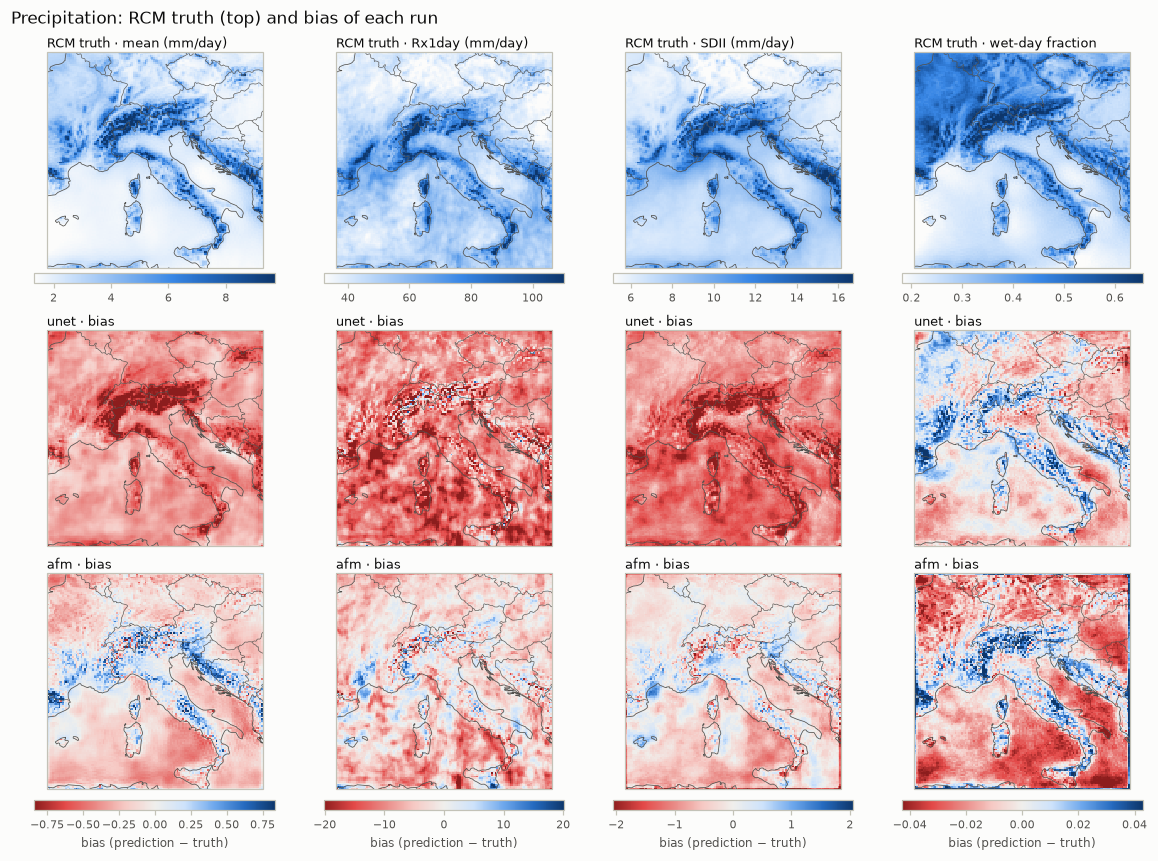

In [10]:
D = {r: results.load_diagnostics(EXP, r, SPLIT) for r in RUNS}
MG = P.MapGrid.from_experiment(EXP, D[RUNS[0]])
cap("precipitation. Top row: RCM truth of the time mean, Rx1day (mean annual maximum), SDII (mean intensity on "
    "days ≥ 1 mm) and wet-day fraction (days ≥ 1 mm). Other rows: bias of each run.")
P.fig_bias_maps(D, "pr", [("mean", "mean (mm/day)"), ("Rx1day", "Rx1day (mm/day)"),
                          ("SDII", "SDII (mm/day)"), ("wetfrac", "wet-day fraction")], MG,
                save=save(f"maps_pr_{SPLIT}"));

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- Truth: mean precipitation, extremes and wet-day frequency are highest over the Alps, the Apennines and the Dinaric Alps.
- **U-Net:** too dry at every grid point, most over high terrain (mean bias −0.78 mm/day above 1000 m, −0.33 below
  300 m). **AFM:** small biases of both signs (28% of grid points too wet): slightly wet over the Alpine ridge and the
  Dinaric Alps (+0.19 mm/day above 1000 m), slightly dry over the lowlands and the sea (−0.16 below 300 m).
- Extremes: Rx1day is underestimated by 10.8 mm/day (U-Net) vs. 3.2 mm/day (AFM) on average, against a truth of
  52 mm/day; SDII by 1.20 vs. 0.22 mm/day.
- Wet-day fraction: the AFM has slightly too few wet days over the sea and the plains and too many over the mountains
  (domain mean −0.01). Its outermost two grid rows have more drizzle than the interior (wet-day fraction +0.017 vs.
  −0.010, SDII −0.76 vs. −0.18 mm/day): a thin frame visible in the maps, an edge effect of the network.

**Shown:** daily maximum temperature. Top row: RCM truth of the time mean, TXx (mean annual maximum), 99th percentile and IAV (standard deviation of annual means). Other rows: bias of each run.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

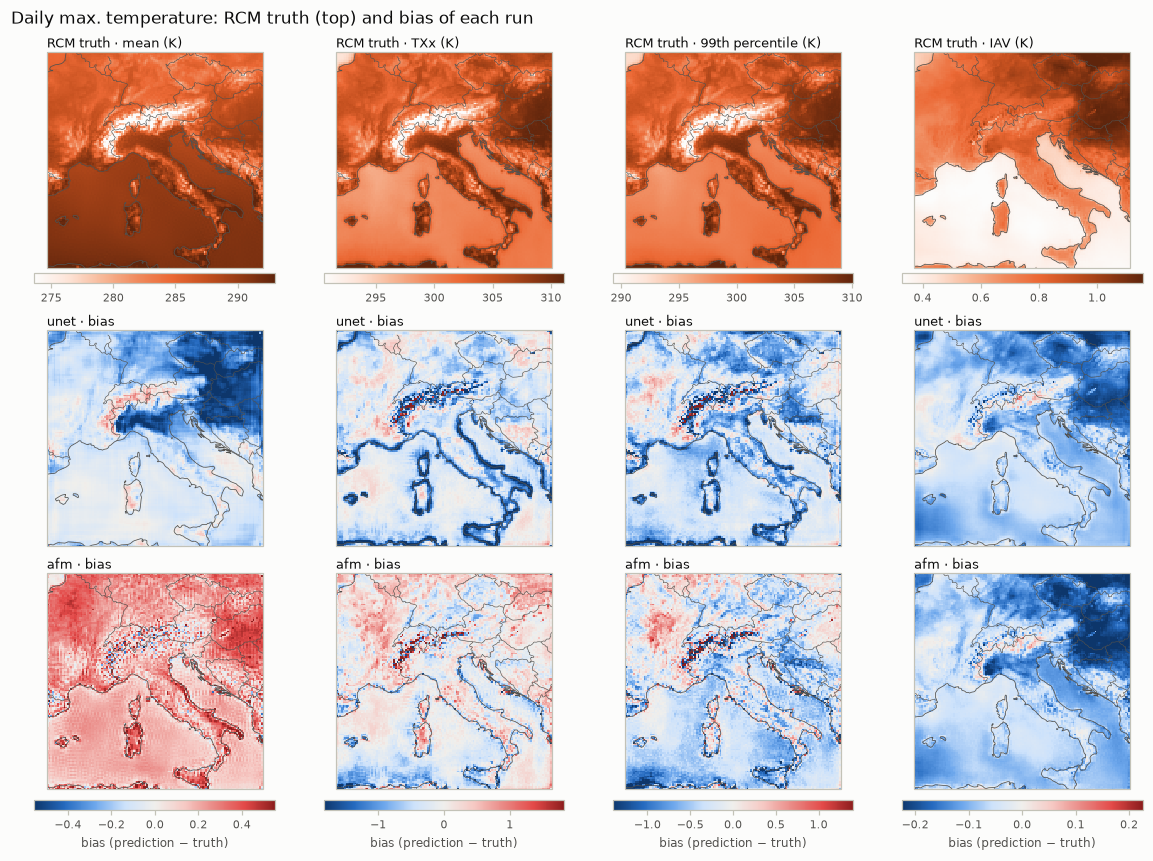

In [11]:
cap("daily maximum temperature. Top row: RCM truth of the time mean, TXx (mean annual maximum), 99th percentile "
    "and IAV (standard deviation of annual means). Other rows: bias of each run.")
P.fig_bias_maps(D, "tasmax", [("mean", "mean (K)"), ("TXx", "TXx (K)"),
                              ("p99", "99th percentile (K)"), ("IAV", "IAV (K)")], MG,
                save=save(f"maps_tasmax_{SPLIT}"));

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- Truth: orography dominates the mean and the extremes; interannual variability is largest in the continental northeast.
- Mean biases are small and of opposite sign: the U-Net is slightly too cold (−0.17 K domain mean; 90% of grid points
  between −0.52 and +0.02 K), most in the northeast; the AFM slightly too warm almost everywhere (+0.21 K; 0.00 to
  +0.43 K), most over land.
- Hot extremes: the AFM's TXx is unbiased on average (−0.01 K; locally −4.5 to +6.3 K over the high Alps), the
  U-Net's is 0.40 K too low, with a cold band along the coastlines that is much weaker in the AFM.
- Both underestimate interannual variability by a similar amount (IAV −0.08 K U-Net, −0.09 K AFM).

**Shown:** day-to-day skill at every grid point: RMSE (first and third figure; ensemble mean for stochastic runs) and temporal correlation with the truth (second and fourth). Correlation colour scales start at 0.5 (pr) and 0.9 (tasmax); lower values share the lightest colour.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

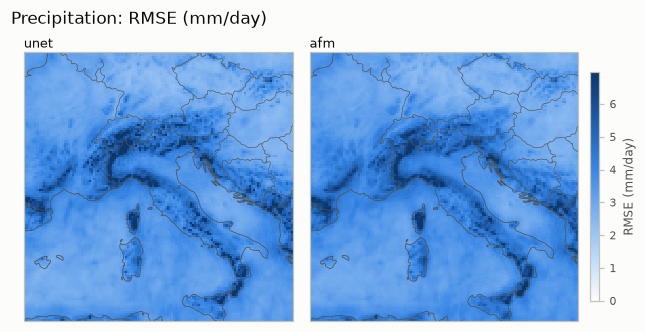

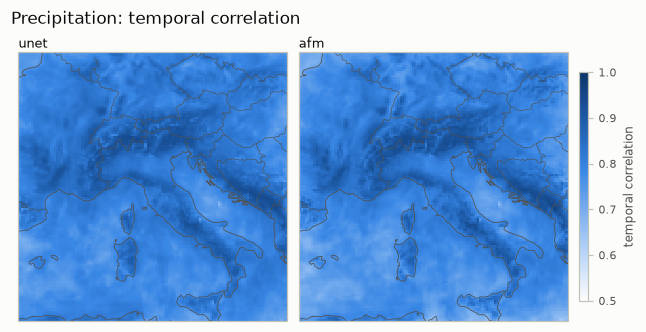

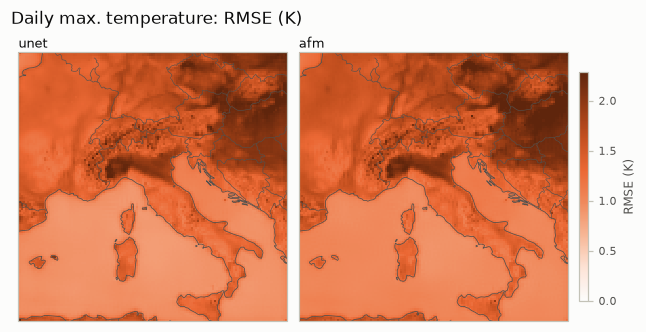

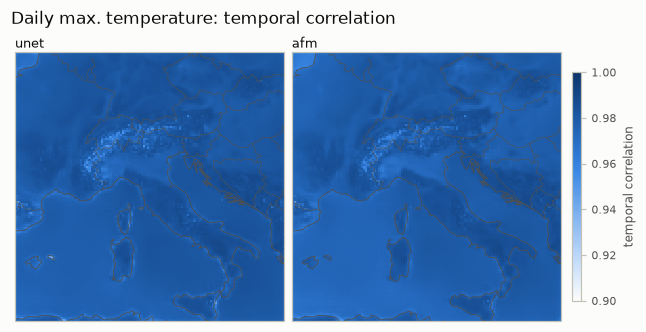

In [12]:
cap("day-to-day skill at every grid point: RMSE (first and third figure; ensemble mean for stochastic runs) and "
    "temporal correlation with the truth (second and fourth). Correlation colour scales start at 0.5 (pr) and 0.9 "
    "(tasmax); lower values share the lightest colour.")
for var in EXP.variables:
    P.fig_field_maps(D, var, "rmse_map", f"RMSE ({P.UNITS[var]})", MG, cmap=P.SEQ[var], vmin=0,
                     save=save(f"rmse_{var}_{SPLIT}"))
    plt.show()
    P.fig_field_maps(D, var, "corr_map", "temporal correlation", MG, cmap=P.SEQ["pr"],
                     vmin={"pr": 0.5, "tasmax": 0.9}.get(var, 0), vmax=1, save=save(f"corr_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- The two models' error maps are nearly identical. pr RMSE follows the precipitation amount: largest over the
  mountains, smallest over the sea and the plains (domain mean 3.62 mm/day U-Net, 3.72 AFM ensemble mean; highest
  grid point 13.6 vs. 10.2).
- pr correlation: U-Net 0.81 on average (lowest grid point 0.68), AFM 0.80 (0.63); for both highest over the
  mountains, where orographic rain follows the large-scale flow, and lowest over the Tyrrhenian Sea and the Adriatic.
- tasmax: RMSE 1.35 vs. 1.41 K (domain mean), correlation above 0.94 at every grid point for both (0.980 vs. 0.978).
- Part of the AFM's small RMSE gap is sampling noise: a 12-member mean still retains 1/12 of the member variance.
  The AFM's encoder alone is much less accurate than the U-Net (validation RMSE pr 4.62 mm/day, tasmax 2.39 K); it
  only provides the starting point for the flow.

## 5. Example days

The wettest winter (DJF) day, the wettest summer (JJA) day and the hottest day of the test period (by domain mean of
the truth). Deterministic models show the conditional mean, so they are expected to look smoother than the truth;
a generative model should look like a plausible weather map, not necessarily like this particular one.

**Shown:** single days: pr on 1997-12-06 and 1992-08-28 (log colour scale, < 0.5 mm/day white), tasmax on 2000-08-26; truth (left), each deterministic run, and for ensembles two members and the ensemble mean.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

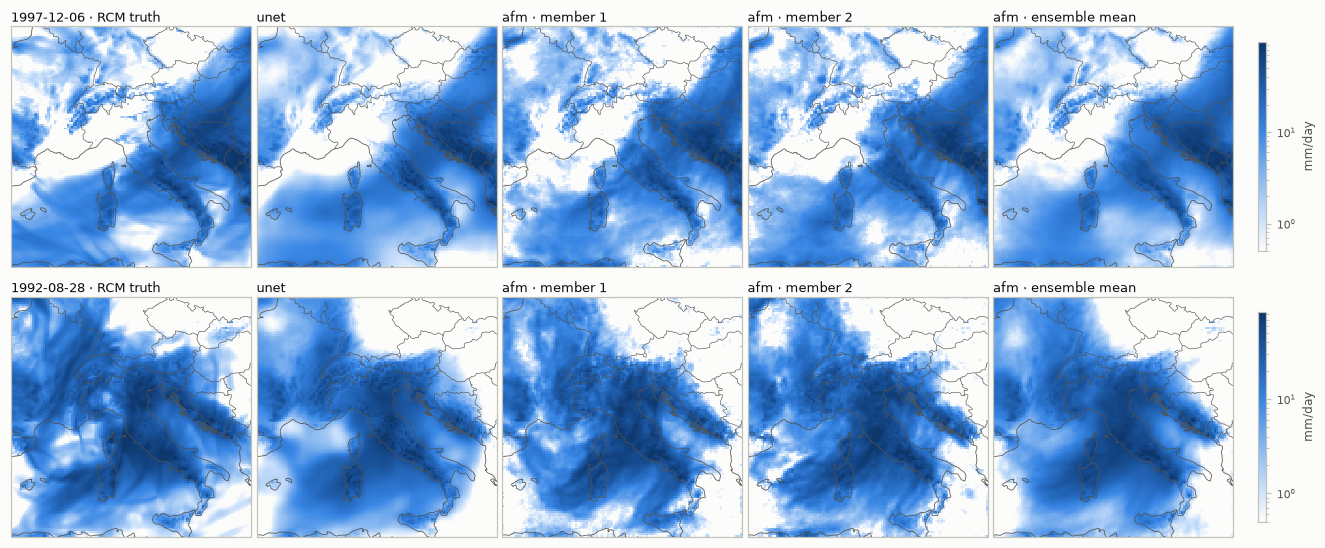

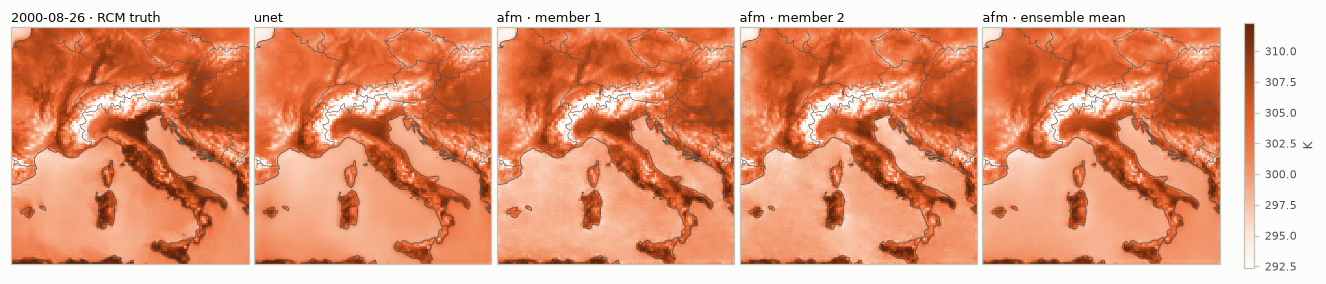

In [13]:
d0 = D[RUNS[0]]
time = pd.DatetimeIndex(d0["time"].values)
pr_dm, tx_dm = d0["pr_series_true"].values, d0["tasmax_series_true"].values
djf, jja = time.month.isin([12, 1, 2]), time.month.isin([6, 7, 8])
dates = [time[djf][np.argmax(pr_dm[djf])], time[jja][np.argmax(pr_dm[jja])], time[np.argmax(tx_dm)]]
cap(f"single days: pr on {dates[0]:%Y-%m-%d} and {dates[1]:%Y-%m-%d} (log colour scale, < 0.5 mm/day white), "
    f"tasmax on {dates[2]:%Y-%m-%d}; truth (left), each deterministic run, and for ensembles two members and the "
    "ensemble mean.")
n_mem = scores.groupby("run").n_members.max()
for var, days in [("pr", dates[:2]), ("tasmax", dates[2:])]:
    truth = results.load_fields(EXP, SPLIT, days, var)
    preds = {}
    for r in RUNS:
        if n_mem.get(r, 1) > 1:
            for k in (0, 1):
                preds[f"{r} · member {k + 1}"] = results.load_fields(EXP, SPLIT, days, var, run=r, member=k)
            preds[f"{r} · ensemble mean"] = results.load_fields(EXP, SPLIT, days, var, run=r, member="mean")
        else:
            preds[r] = results.load_fields(EXP, SPLIT, days, var, run=r)
    P.fig_example_days(truth, preds, days, var, MG, save=save(f"days_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- Both models place the weather correctly: the frontal band over the Adriatic and the Balkans in December, the
  widespread rain over the Alps, Italy and the Mediterranean in August, and the pattern of the hottest day.
- The U-Net and the AFM ensemble mean are smooth. Single AFM members have RCM-like texture: sharp rain edges and
  dry gaps. The members differ from each other in these details, not in the large-scale pattern.
- All twelve members agree closely on the domain-mean amount, and all are too low on these extreme days: 9.4–9.6 vs.
  10.9 mm/day (December) and 12.8–13.0 vs. 15.3 mm/day (August); U-Net 9.3 and 12.0. Local peaks are realistic: the
  members' maxima are 140–172 and 128–150 mm/day vs. 177 and 136 in the truth.
- Hottest day: domain mean 28.8–28.9 °C in all members, 28.6 °C U-Net, 29.9 °C truth.

## 6. Spatial structure: power spectra

Mean radially averaged power spectrum of the daily fields (one member). The right panel is the ratio to the truth in
dB; below 0 dB means too little variance at that scale (too smooth). The published RALSD is the mean square of this
curve over **all 90 bins**, including the 25 bins beyond the Nyquist wavenumber (shaded): the grid's diagonal
"corners", i.e. pixel-scale texture. The table splits RALSD into the two parts.

**Shown:** mean radial power spectra (left) and spectral ratio prediction/truth in dB (right) for pr (first figure) and tasmax (second); table: RALSD over all bins (= published value), over resolved scales and over the corner bins.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

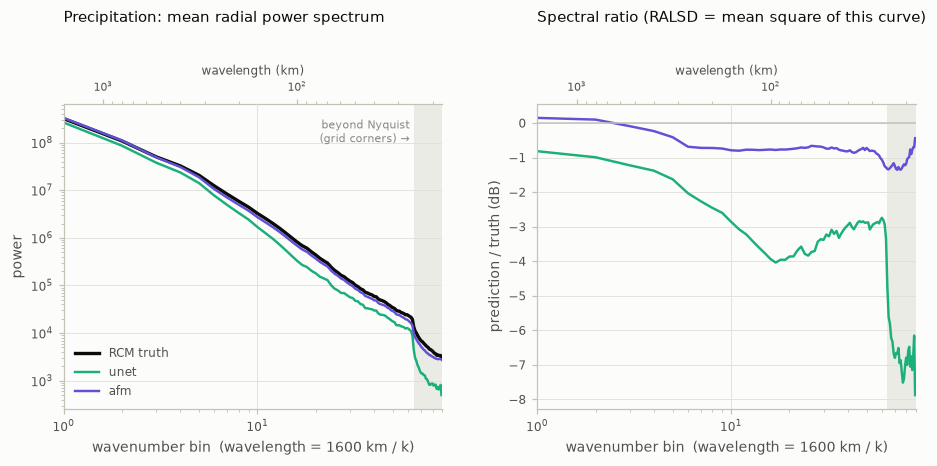

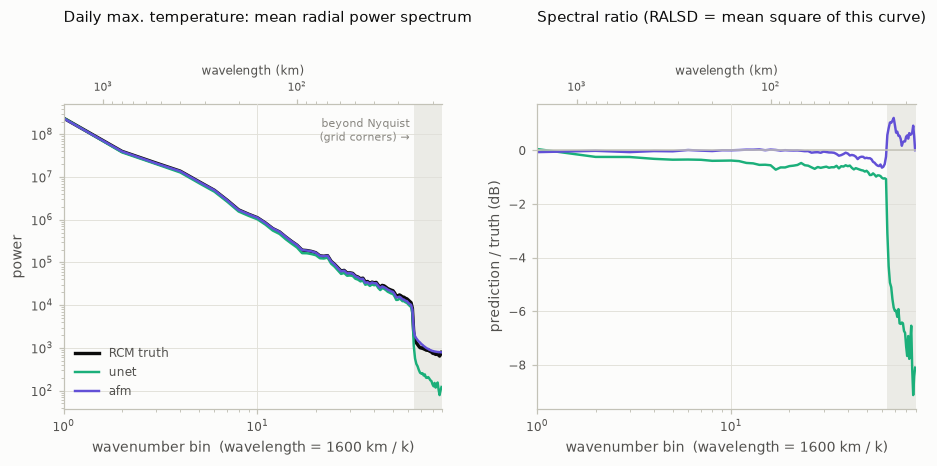

In [14]:
cap("mean radial power spectra (left) and spectral ratio prediction/truth in dB (right) for pr (first figure) and "
    "tasmax (second); table: RALSD over all bins (= published value), over resolved scales and over the corner bins.")
for var in EXP.variables:
    P.fig_spectra(D, var, COLORS, save=save(f"spectra_{var}_{SPLIT}"))
    plt.show()
split_tab = pd.concat({var: pd.DataFrame(P.ralsd_split(D, var)).T for var in EXP.variables}, axis=1)
display(split_tab.style.format(fmt).set_caption("RALSD (dB²)"))

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **pr:** the U-Net lacks variance at every scale (−0.8 to −1.6 dB above 300 km, −2.7 to −4 dB at 30–160 km, −6 to
  −8 dB in the corner bins; RALSD 19.7 dB²). The AFM is close to the truth at the largest scales (+0.1 to −0.4 dB)
  and −0.7 to −1.1 dB from 160 km down to the grid scale, −1.4 to −0.4 dB in the corner bins (RALSD 0.81 dB², 0.62
  over resolved scales).
- **tasmax:** the AFM is within ±0.3 dB up to the Nyquist wavenumber except at the very smallest scales (−0.6 dB)
  and slightly too energetic in the corner bins (0 to +1.2 dB; RALSD 0.18 dB²). The U-Net is 0 to −1 dB below
  Nyquist and −4 to −9 dB in the corner bins (RALSD 13.1 dB²).
- The texture comes from sampling: the spectrum of the AFM *ensemble mean* (not plotted) is 2.5–3.3 dB too low for pr,
  as smooth as the U-Net.

## 7. Distributions and extremes

Left: density over all days and grid points (log scale; pr dry fraction, < 0.1 mm/day, in the legend). Right:
pooled quantiles 0.5 … 0.9999 against the truth; points below the 1:1 line in the upper tail mean extremes are
underestimated.

**Shown:** distribution of all daily values over the whole domain (left) and quantile-quantile plot (right), for pr (first figure) and tasmax (second).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

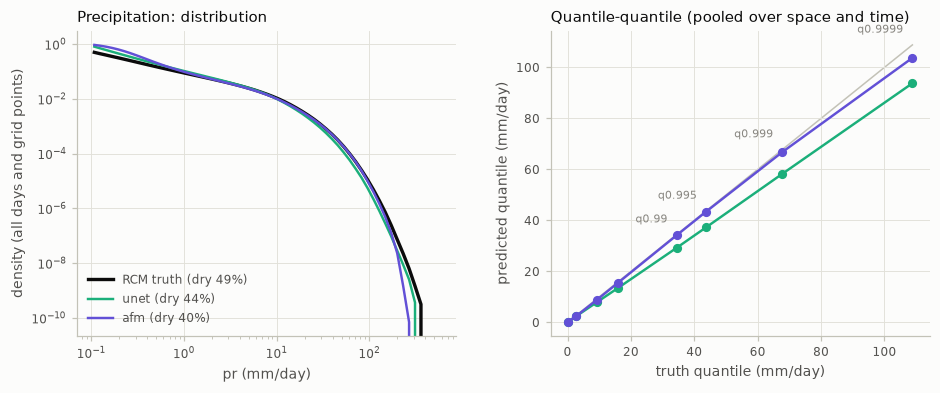

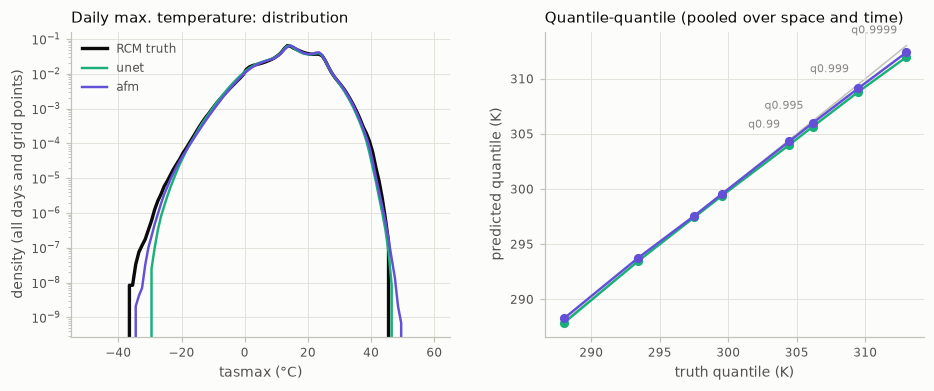

In [15]:
cap("distribution of all daily values over the whole domain (left) and quantile-quantile plot (right), "
    "for pr (first figure) and tasmax (second).")
for var in EXP.variables:
    P.fig_distributions(D, var, COLORS, save=save(f"distributions_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **pr, heavy tail:** the AFM follows the truth up to the 99.9th percentile (99th 34.1 vs. 34.4 mm/day, 99.9th 66.8
  vs. 67.8) and is close at the 99.99th (104 vs. 109); the U-Net is too light throughout (29.2, 58.3, 94). Beyond
  about 150 mm/day the AFM has too few values: one member has 27 grid-point days ≥ 200 mm/day against 213 in the
  truth, and its maximum is 233 vs. 368 mm/day. This far tail is what makes its LHD poor.
- **pr, light rain:** the RCM is dry (< 0.1 mm/day) on 49% of grid-point days, the U-Net on 44%, the AFM on only 40%.
  The AFM's extra values are traces between 0.1 and 1 mm/day (the wet-day fraction at 1 mm/day is nearly unbiased),
  most likely sampling noise that survives where negative values are clipped at 0.
- **tasmax:** both reproduce the distribution well (PSS 0.97–0.98). The AFM gets the cold tail closer to the truth;
  its hot tail reaches a few kelvin beyond the truth's maximum at a handful of grid-point days (density < 10⁻⁸).
  99.99th percentile 39.2 °C (AFM), 38.8 °C (U-Net), 39.9 °C (truth).

## 8. Seasonal cycle of the bias

**Shown:** domain-mean bias (prediction − truth) per calendar month, pr (left) and tasmax (right).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

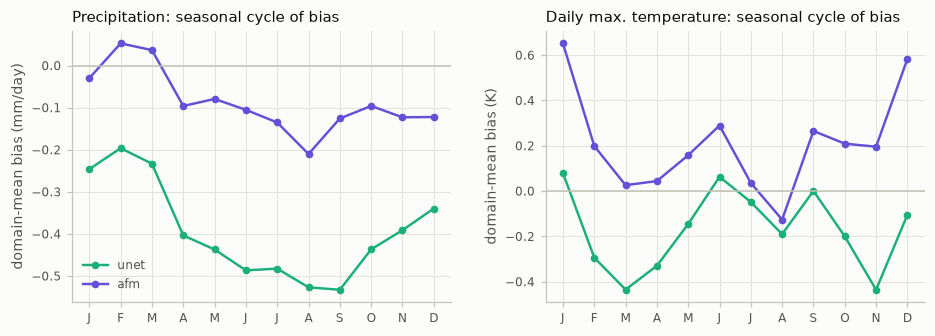

In [16]:
cap("domain-mean bias (prediction − truth) per calendar month, pr (left) and tasmax (right).")
P.fig_seasonal_bias(D, COLORS, EXP.variables, save=save(f"seasonal_{SPLIT}"));

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **pr:** the U-Net is too dry in every month (−0.20 to −0.53 mm/day, most from April to October). The AFM stays
  within −0.21 to +0.05 mm/day, driest in August.
- **tasmax:** the U-Net is slightly cold in February–April and November (−0.29 to −0.44 K). The AFM is slightly warm
  in most months and clearly so in December–January (+0.58 and +0.65 K).
- **Future (not plotted):** in 2080–2099 the AFM is far too cold in July and August (−2.8 and −3.2 K domain mean;
  U-Net −1.4 and −1.6 K), and on the hottest 10% of days by 3.9 K (U-Net 1.9 K). Section 9 shows the consequence for
  the warming signal.

## 9. Climate change signal (extrapolation)

ESD models are trained on 1961–1980 only, so reproducing the future change is an extrapolation test: a model that just
reproduces the training climate shows no change at all.

**Shown:** change of the time mean from `historical_perfect` to `mid_end_century_perfect` (pr in %, tasmax in K): truth and each run (top row), error of each run's change, run − truth (bottom row); table: domain means.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

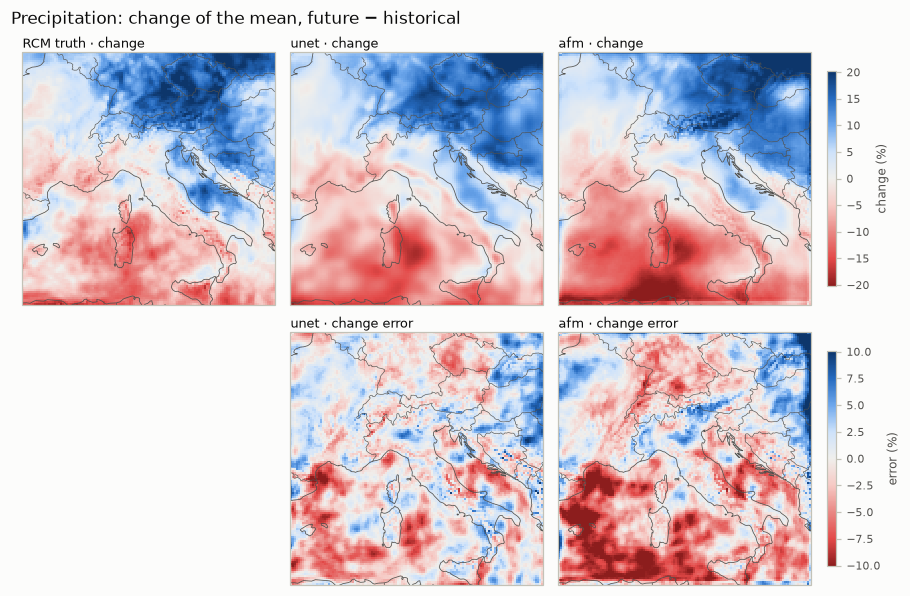

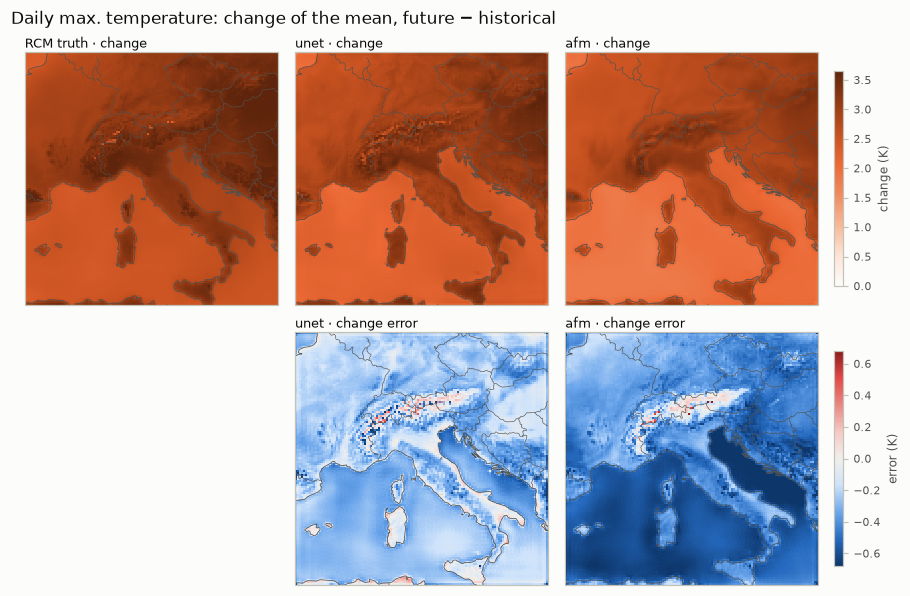

,"pr change (%, domain mean)","tasmax change (K, domain mean)"
model,,
RCM truth,+2.13,+2.97
afm,+0.97,+2.50
unet,+1.93,+2.72


In [17]:
DF = {r: results.load_diagnostics(EXP, r, FUTURE) for r in RUNS}
cap(f"change of the time mean from `{SPLIT}` to `{FUTURE}` (pr in %, tasmax in K): truth and each run (top row), "
    "error of each run's change, run − truth (bottom row); table: domain means.", [SPLIT, FUTURE])
for var in EXP.variables:
    P.fig_change_maps(D, DF, var, MG, save=save(f"change_{var}"))
    plt.show()
rows = []
for var in EXP.variables:
    th, tf = float(D[RUNS[0]][f"{var}_mean_true"].mean()), float(DF[RUNS[0]][f"{var}_mean_true"].mean())
    for name, h, f in [("RCM truth", th, tf)] + [
            (r, th + float(D[r][f"{var}_bias_mean"].mean()), tf + float(DF[r][f"{var}_bias_mean"].mean()))
            for r in RUNS]:
        rows.append({"variable": var, "model": name, "change": 100 * (f - h) / h if var == "pr" else f - h})
change = pd.DataFrame(rows).pivot(index="model", columns="variable", values="change")
change.columns = [f"{v} change ({'%' if v == 'pr' else 'K'}, domain mean)" for v in change.columns]
display(change.style.format("{:+.2f}"))

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- Truth: tasmax warms by 3.0 K on average, more over the northern land areas than over the sea. pr shows a
  north–south dipole: +10–15% north of the Alps, about −10% over the Mediterranean; +2.1% domain mean.
- **tasmax:** both underestimate the warming: U-Net +2.72 K, AFM +2.50 K vs. +2.97 K. The AFM's deficit is largest
  over the Mediterranean and the Adriatic (−0.4 to −0.6 K); the spatial pattern is captured by both (correlation with
  the true change 0.962 and 0.955). The AFM misses warming because it is too cold on hot summer days at the end of
  the century (section 8). Those temperatures lie outside the 1961–1980 training distribution; most likely the
  generative model pulls them back towards it more strongly than the U-Net does. This is the extrapolation weakness the ESD test is
  designed to expose; training on a warmer climate (the Emulator experiment) is the obvious remedy.
- **pr:** the U-Net reproduces the dipole well (+1.9% domain mean, pattern correlation 0.94). The AFM makes the drying
  in the south and southwest too strong (+1.0% domain mean, pattern correlation 0.92).

## 10. Ensemble calibration

Only for stochastic runs (more than one member): rank histograms (flat = calibrated, U-shape = under-dispersive,
dome = over-dispersive), spread/skill ratio and CRPS.

**Shown:** rank histograms of the truth among the ensemble members (every 4th grid point, all days).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** unet, afm (12 members)

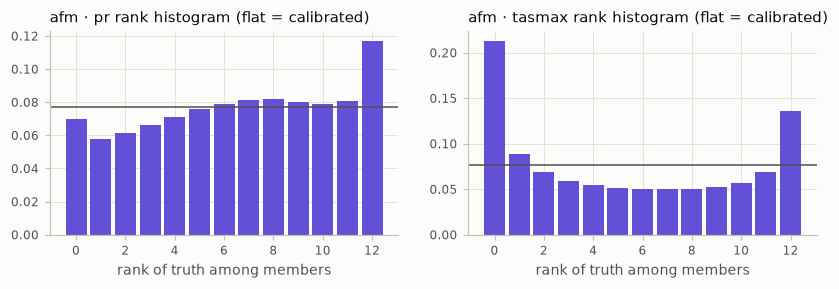

In [18]:
stoch = [r for r in RUNS if scores[(scores.run == r)].n_members.max() > 1]
if not stoch:
    print("No stochastic runs evaluated yet.")
else:
    cap("rank histograms of the truth among the ensemble members (every 4th grid point, all days).")
    P.fig_rank_histograms({r: D[r] for r in stoch}, COLORS, EXP.variables, save=save(f"rank_hist_{SPLIT}"))
    plt.show()
    s = scores[(scores.split == SPLIT) & scores.run.isin(stoch) & scores.metric.isin(["CRPS", "Spread/skill"])]
    display(s.pivot_table(index="run", columns=["variable", "metric"], values="value").style.format(fmt))

**Findings** *(snapshot 2026-11-02, runs: unet, afm; update when runs change)*
- **The AFM ensemble is under-dispersive:** its spread is about 60% of the ensemble-mean error (spread/skill 0.62
  for pr, 0.59 for tasmax; ideal 1). The members vary small-scale detail but agree on large-scale amounts
  (section 5), so they miss days on which the whole region is wetter or warmer than predicted.
- **tasmax:** a U-shaped histogram: the truth lies below all 12 members in 21% of cases and above all in 14% (7.7%
  each if calibrated). The asymmetry reflects the +0.2 K warm bias.
- **pr:** nearly flat in the middle (ties at 0 mm are broken at random), but the truth exceeds all members in 12% of
  cases: heavy rain is under-represented, consistent with the far tail in section 7.
- Even so, the AFM's CRPS is 23–24% lower than the U-Net's (section 3). In the future period the calibration gets
  worse for tasmax (spread/skill 0.48; truth above all 5 members in 33% of cases instead of 17%).
- MCB (Debeire et al. 2026) is 0.0002 (pr) and 0.002 (tasmax); it averages squared deviations over many bins and
  is therefore small even for the clearly U-shaped tasmax histogram.

---
**Adding a model.** Implement a `Downscaler` subclass in `src/dslab/models/` (see `linear.py` or `unet.py`),
register it, add `configs/models/<name>.yaml`, then `bash jobs/submit_model.sh alps_esd <name>` (GPU training,
then evaluation) and `sbatch jobs/notebook.sbatch`. The run appears here automatically; update the findings notes.
Pin its colour with `P.RUN_COLORS["<name>"] = P.SERIES[k]` before `run_colors`.